# Lab 2 – Temporal Difference control: SARSA and Q-learning

**Tasks**
1. Implement Q-learning and SARSA for the CliffWalking environment.
2. Visualize the best policy (sequence of images / video).

**Environment (CliffWalking):** 4×12 grid, start `S` = state 36 (bottom-left), goal `G` = state 47 (bottom-right).
Every step costs **−1**, stepping into the cliff costs **−100** and sends the agent back to `S`.
Actions: `0 = up, 1 = right, 2 = down, 3 = left`. State id = `row * 12 + col`.

In [3]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Environment id
# Newer gymnasium versions (>= 1.1) removed 'CliffWalking-v0' and raise
# DeprecatedEnv. 'CliffWalking-v1' is the same environment (it only adds an
# optional is_slippery flag, False by default). Pick whichever is available,
# so the notebook works on any gymnasium version (Colab installs the newest).
# ---------------------------------------------------------------------------
ENV_ID = 'CliffWalking-v1' if 'CliffWalking-v1' in gym.registry else 'CliffWalking-v0'
print('Using', ENV_ID, '| gymnasium', gym.__version__)

# Fixed seed -> the same results every time the notebook is run
np.random.seed(42)


def render_as_image(env):
    """Show the current frame of the environment as a single image."""
    plt.figure(figsize=(6, 2))
    plt.imshow(env.render())
    plt.axis('off')
    plt.show()


Using CliffWalking-v1 | gymnasium 1.4.0


## Q-table and agent

* `Qtable` – Q(s, a) stored as a 48 × 4 numpy array.
* `chooseActionEpsilonGreedyPolicy` – random action with probability ε, otherwise the best one.
* `playQ_learning` – off-policy TD control: target `r + γ·max_a' Q(s', a')`.
* `play_SARSA` – on-policy TD control: target `r + γ·Q(s', a')`, where `a'` is the action really taken next.

In [4]:
DEFAULT_QVALUE = 0
NEGATIVE_INF = -100


class Qtable:
    """
    Tabular action-value function Q(s, a).

    CliffWalking has 48 discrete states (4 rows x 12 columns, state = row*12 + col)
    and 4 discrete actions (0=up, 1=right, 2=down, 3=left), so the whole table
    is a 48 x 4 numpy array:  self.q[state, action] = Q(s, a)
    """

    def __init__(self, environment=None):
        self.n_states = environment.observation_space.n      # 48
        self.n_actions = environment.action_space.n           # 4
        # Q(s, a) = 0 for all pairs at the start (also for the terminal state,
        # which must stay 0 - it is never updated, because we never act from it)
        self.q = np.full((self.n_states, self.n_actions), DEFAULT_QVALUE, dtype=float)

    def set_qvalue(self, state, action, value):
        self.q[state, action] = value

    def get_qvalue(self, state, action):
        return self.q[state, action]

    def get_max_qvalue(self, state):
        # max_a Q(s, a)  -> used by Q-learning as the "best possible future"
        return np.max(self.q[state])

    # get action values as vector indexed by env action space
    def get_qvalue_vector(self, state):
        # [Q(s,up), Q(s,right), Q(s,down), Q(s,left)]
        return self.q[state].copy()

    # get state values as maximum from state-action values originating from state
    def get_state_values(self):
        # V(s) = max_a Q(s, a)  -> dict {state_id: value}, used by showValues()
        return {s: float(np.max(self.q[s])) for s in range(self.n_states)}


class Agent:

    def __init__(self):
        self.current_state = None
        self.environment = gym.make(ENV_ID)

        self.lr = 0.01            # alpha - learning rate (step size)
        self.exp_rate = 0.3       # epsilon - probability of a random (exploratory) action
        self.decay_gamma = 1.0    # gamma - discount factor

        # initial state reward
        self.state_values = {}
        self.state_visit_count = {}

        # initial Q values
        self.Q_values = Qtable(self.environment)

        # sum of rewards of every training episode (for learning curves)
        self.episode_rewards = []

    def end_training(self):
        self.environment.close()

    # =====================================================================
    # Q-LEARNING  (off-policy TD control)
    #   Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]
    # =====================================================================
    def playQ_learning(self, number_of_episodes=1):

        episode_count = 0

        while episode_count < number_of_episodes:
            i = 0
            terminated = False

            self.reset()
            R = 0
            while terminated == False:
                state = self.current_state

                # 1. BEHAVIOUR policy: epsilon-greedy (explores)
                action = self.chooseActionEpsilonGreedyPolicy(state, self.exp_rate)

                # 2. Act in the environment, observe reward and next state
                next_state, reward, terminated, truncated, info = self.environment.step(action)

                # 3. TD target uses the BEST action in s' (greedy TARGET policy),
                #    no matter which action the agent will really take next -> off-policy.
                #    In a terminal state there is no future, so the target is just r.
                if terminated:
                    td_target = reward
                else:
                    td_target = reward + self.decay_gamma * self.Q_values.get_max_qvalue(next_state)

                # 4. Move Q(s,a) a step of size alpha towards the target
                old_q = self.Q_values.get_qvalue(state, action)
                td_error = td_target - old_q
                self.Q_values.set_qvalue(state, action, old_q + self.lr * td_error)

                # 5. Go to the next state
                R += reward
                i += 1
                self.current_state = next_state
                if truncated:          # time limit (not used by CliffWalking, but safe)
                    break

            self.episode_rewards.append(R)
            episode_count += 1

        self.state_values = self.Q_values.get_state_values()
        self.end_training()

    # =====================================================================
    # SARSA  (on-policy TD control)
    #   Q(s,a) <- Q(s,a) + alpha * [ r + gamma * Q(s',a') - Q(s,a) ]
    #   name = the 5 values used in one update: S, A, R, S', A'
    # =====================================================================
    def play_SARSA(self, number_of_episodes=1):

        episode_count = 0

        while episode_count < number_of_episodes:
            i = 0
            terminated = False

            self.reset()
            R = 0
            # SARSA needs the first action BEFORE the loop
            action = self.chooseActionEpsilonGreedyPolicy(self.current_state, self.exp_rate)

            while terminated == False:
                state = self.current_state

                # 1. Act, observe reward and next state
                next_state, reward, terminated, truncated, info = self.environment.step(action)

                # 2. Choose the NEXT action with the SAME epsilon-greedy policy
                #    (this action will really be executed in the next step)
                next_action = self.chooseActionEpsilonGreedyPolicy(next_state, self.exp_rate)

                # 3. TD target uses Q of the action we will REALLY take -> on-policy.
                #    Random steps towards the cliff lower Q here, so SARSA learns
                #    to keep a safe distance from the cliff.
                if terminated:
                    td_target = reward
                else:
                    td_target = reward + self.decay_gamma * self.Q_values.get_qvalue(next_state, next_action)

                # 4. Update Q(s,a)
                old_q = self.Q_values.get_qvalue(state, action)
                td_error = td_target - old_q
                self.Q_values.set_qvalue(state, action, old_q + self.lr * td_error)

                # 5. S <- S',  A <- A'
                R += reward
                i += 1
                self.current_state = next_state
                action = next_action
                if truncated:
                    break

            self.episode_rewards.append(R)
            episode_count += 1

        self.state_values = self.Q_values.get_state_values()
        self.end_training()

    def follow_best_policy(self, show_images=True, max_steps=100):
        """
        Run ONE episode with the greedy policy (epsilon = 0) and show every step
        as an image. Frames are also stored in self.frames (used for the video).
        max_steps protects against an endless loop if the policy is not learned yet.
        """
        self.environment = gym.make(ENV_ID, render_mode='rgb_array')

        self.current_state = self.environment.reset()[0]
        self.frames = [self.environment.render()]
        self.path = [self.current_state]
        i = 0
        R = 0.0
        terminated = False
        while terminated == False and i < max_steps:
            if show_images:
                render_as_image(self.environment)
                print('State: ', self.current_state, '  ', self.Q_values.get_qvalue_vector(self.current_state))

            action = self.chooseActionEpsilonGreedyPolicy(self.current_state, 0.0)  # epsilon = 0 => strictly greedy policy
            next_state, reward, terminated, truncated, info = self.environment.step(action)
            if show_images:
                print(f'Step {i}: observation={next_state}, reward={reward}, done={terminated}')

            R = R + reward
            i = i + 1
            self.current_state = next_state
            self.frames.append(self.environment.render())
            self.path.append(next_state)

        if show_images:
            render_as_image(self.environment)      # final frame (agent in the goal)
        print("Reward ", R, "| steps", i)
        self.environment.close()
        return R

    def chooseActionEpsilonGreedyPolicy(self, state, epsilon):
        """
        Epsilon-greedy:
          with probability epsilon     -> random action    (exploration)
          with probability 1 - epsilon -> best known action (exploitation)
        Ties between equally good actions are broken randomly
        (np.argmax would always pick the first one, e.g. always 'up' at the start).
        """
        if np.random.random() < epsilon:
            action = np.random.randint(self.Q_values.n_actions)
        else:
            q = self.Q_values.get_qvalue_vector(state)
            best_actions = np.flatnonzero(q == q.max())
            action = int(np.random.choice(best_actions))

        return action

    def reset(self):
        self.states_visited_trace = []
        self.states_reward_trace = []
        self.current_state = self.environment.reset()[0]

    def showValues(self):
        BOARD_ROWS = 4
        BOARD_COLS = 12

        print('---------STATE VALUES------------')
        for i in range(0, BOARD_ROWS):
            print('----------------------------------')
            out = '| '
            for j in range(0, BOARD_COLS):
                state_id = i * 12 + j
                if (state_id) in self.state_values.keys():
                    value = self.state_values[state_id]
                else:
                    value = 0.0
                out += "{0:0.2f}".format(value).ljust(6) + ' | '
            print(out)
        print('----------------------------------')


## Visualization helpers

* `plot_policy_map` – color = V(s) = max Q(s, a), arrow = greedy action, blue line = greedy path
* `show_filmstrip` – the whole episode as a grid of images
* `show_animation` – the episode as an animated GIF (video)
* `plot_learning_curves` – reward per training episode

In [4]:
import imageio
from IPython.display import Image, display

ROWS, COLS = 4, 12
START, GOAL = 36, 47
CLIFF = set(range(37, 47))                       # bottom row between S and G
ARROW = {0: (0, -0.32), 1: (0.32, 0), 2: (0, 0.32), 3: (-0.32, 0)}   # up, right, down, left (dx, dy)


def greedy_path(agent, max_steps=100):
    """States visited when following the greedy policy from the start."""
    s, path = START, [START]
    for _ in range(max_steps):
        if s == GOAL:
            break
        a = int(np.argmax(agent.Q_values.get_qvalue_vector(s)))
        r, c = divmod(s, COLS)
        dr, dc = [(-1, 0), (0, 1), (1, 0), (0, -1)][a]
        r, c = min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1)
        s = r * COLS + c
        if s in CLIFF:                           # falling off the cliff -> back to start
            s = START
        path.append(s)
    return path


def plot_policy_map(agent, title, ax=None):
    """Grid 4x12: color = V(s) = max_a Q(s,a), arrow = greedy action, blue line = greedy path."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4.2))
    V = np.array([agent.Q_values.get_max_qvalue(s) for s in range(ROWS * COLS)]).reshape(ROWS, COLS)
    V_masked = np.ma.masked_array(V, mask=np.zeros_like(V, bool))
    for s in CLIFF:
        V_masked.mask[divmod(s, COLS)] = True
    cmap = plt.get_cmap('RdYlGn').copy()
    cmap.set_bad('#2b2b2b')                      # cliff cells = dark
    im = ax.imshow(V_masked, cmap=cmap, vmin=np.percentile(V, 5), vmax=0)

    for s in range(ROWS * COLS):
        r, c = divmod(s, COLS)
        if s in CLIFF:
            ax.text(c, r, 'cliff', ha='center', va='center', color='#ff6b6b', fontsize=8)
            continue
        if s == GOAL:
            ax.text(c, r, 'G', ha='center', va='center', fontsize=16, fontweight='bold')
            continue
        a = int(np.argmax(agent.Q_values.get_qvalue_vector(s)))
        dx, dy = ARROW[a]
        ax.arrow(c - dx / 2, r - dy / 2, dx, dy, head_width=0.15, head_length=0.12,
                 color='black', length_includes_head=True)
        ax.text(c + 0.45, r - 0.42, f'{V[r, c]:.0f}', ha='right', va='top', fontsize=7, color='#333')   # value in the corner
    ax.text(0, 3, 'S', ha='left', va='top', fontsize=12, fontweight='bold', color='navy')

    path = greedy_path(agent)
    ys, xs = zip(*[divmod(s, COLS) for s in path])
    ax.plot(xs, ys, color='#1f6feb', lw=4, alpha=0.55)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-0.5, COLS), minor=True); ax.set_yticks(np.arange(-0.5, ROWS), minor=True)
    ax.grid(which='minor', color='white', lw=1.5); ax.tick_params(which='minor', length=0)
    ax.set_title(f'{title}   |   greedy path: {len(path) - 1} steps, return {-(len(path) - 1)}')
    plt.colorbar(im, ax=ax, fraction=0.015, label='V(s) = max Q(s,a)')
    return ax


def show_filmstrip(frames, title, cols=4):
    """All frames of one episode as a grid of small images (sequence of images)."""
    rows = int(np.ceil(len(frames) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 1.5 * rows))
    for k, ax in enumerate(np.ravel(axes)):
        ax.axis('off')
        if k < len(frames):
            ax.imshow(frames[k])
            ax.set_title(f'step {k}', fontsize=9)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


def show_animation(frames, filename, fps=4):
    """Save frames as an animated GIF and show it in the notebook (works in Colab, Jupyter, VS Code)."""
    frames = list(frames) + [frames[-1]] * fps   # hold the last frame for 1 s
    imageio.mimsave(filename, frames, duration=1000 / fps, loop=0)
    display(Image(filename=filename))


def plot_learning_curves(curves, window=50):
    """Sum of rewards per training episode (moving average) for several agents."""
    plt.figure(figsize=(10, 4))
    for name, rewards in curves.items():
        r = np.asarray(rewards, dtype=float)
        smooth = np.convolve(r, np.ones(window) / window, mode='valid')
        plt.plot(np.arange(window, len(r) + 1), smooth, label=name, lw=2)
    plt.ylim(-250, 0)
    plt.xlabel('episode'); plt.ylabel(f'sum of rewards (moving avg, {window} ep.)')
    plt.title('Reward collected DURING training (epsilon-greedy behaviour)')
    plt.grid(alpha=0.3); plt.legend()
    plt.show()


## SARSA (on-policy)

$$Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \alpha\,[\,r_{t+1} + \gamma\, Q(s_{t+1},a_{t+1}) - Q(s_t,a_t)\,]$$

Hyperparameters: α = 0.1, ε = 0.3, γ = 1, 2000 episodes.
With the template values (α = 0.5, 500 episodes) SARSA's Q-values are too noisy – in about half of the runs the greedy
policy gets stuck bumping into a wall. α = 0.1 averages over more episodes and gives a stable policy.

In [5]:
np.random.seed(42)
agent_sarsa = Agent()
agent_sarsa.lr = 0.1          # alpha
agent_sarsa.exp_rate = 0.3    # epsilon
agent_sarsa.play_SARSA(2000)
agent_sarsa.showValues()

---------STATE VALUES------------
----------------------------------
| -21.48 | -19.73 | -18.51 | -17.23 | -15.36 | -13.99 | -12.28 | -10.32 | -9.21  | -7.99  | -6.54  | -5.47  | 
----------------------------------
| -23.22 | -23.06 | -20.21 | -18.01 | -16.61 | -15.45 | -13.84 | -10.91 | -9.21  | -6.75  | -5.00  | -3.30  | 
----------------------------------
| -25.16 | -24.81 | -21.91 | -20.23 | -16.10 | -14.16 | -16.39 | -12.30 | -10.85 | -9.47  | -3.30  | -1.00  | 
----------------------------------
| -28.65 | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 
----------------------------------


### Best SARSA policy – sequence of images

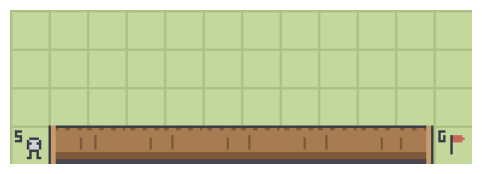

State:  36    [ -28.64719259 -141.43582765  -46.07484785  -54.33658727]
Step 0: observation=24, reward=-1, done=False


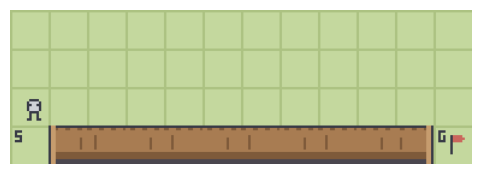

State:  24    [-25.15585258 -31.85783505 -47.20103051 -29.59998063]
Step 1: observation=12, reward=-1, done=False


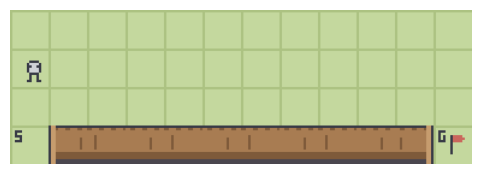

State:  12    [-23.22109369 -25.561489   -28.97106295 -24.51422911]
Step 2: observation=0, reward=-1, done=False


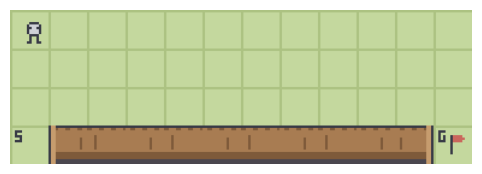

State:  0    [-23.57435926 -21.47588211 -25.46237912 -23.28914731]
Step 3: observation=1, reward=-1, done=False


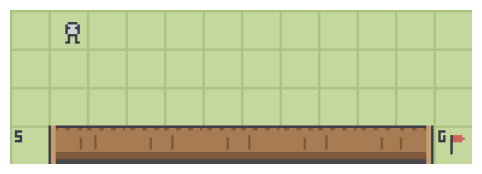

State:  1    [-21.65960505 -19.72611118 -24.43634674 -23.42449834]
Step 4: observation=2, reward=-1, done=False


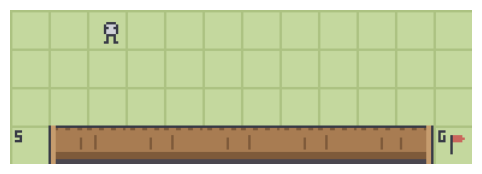

State:  2    [-20.15770522 -18.50700161 -22.15503133 -22.41001702]
Step 5: observation=3, reward=-1, done=False


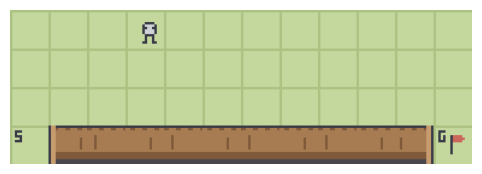

State:  3    [-18.68229907 -17.22545744 -20.93594077 -20.10020438]
Step 6: observation=4, reward=-1, done=False


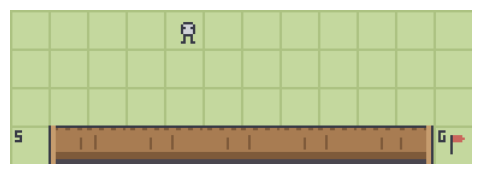

State:  4    [-17.20350785 -15.35834479 -18.7157986  -19.08089141]
Step 7: observation=5, reward=-1, done=False


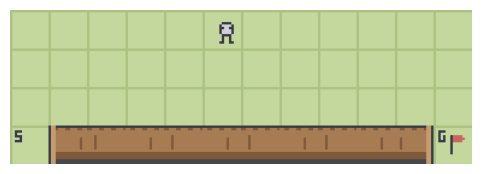

State:  5    [-15.55289069 -13.9870211  -17.31308047 -17.1904001 ]
Step 8: observation=6, reward=-1, done=False


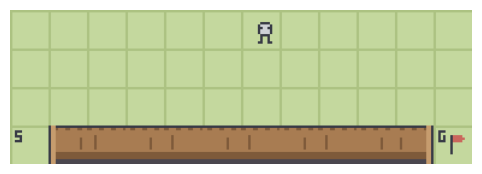

State:  6    [-13.77826986 -12.28354413 -15.24256275 -15.6403199 ]
Step 9: observation=7, reward=-1, done=False


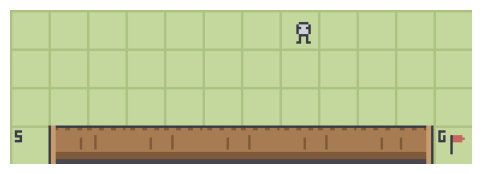

State:  7    [-12.08067729 -10.32196381 -12.78273946 -14.0017603 ]
Step 10: observation=8, reward=-1, done=False


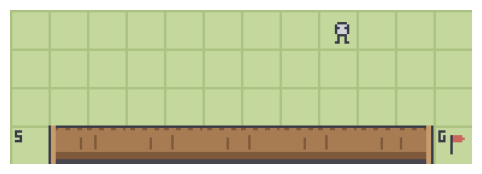

State:  8    [-10.58539158  -9.21161569 -10.31197933 -12.5021728 ]
Step 11: observation=9, reward=-1, done=False


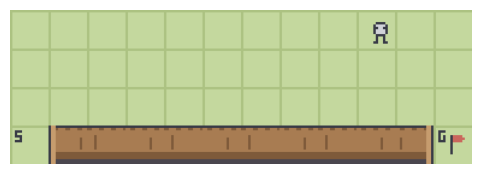

State:  9    [ -9.57264858  -7.99324317  -9.40644393 -10.78792603]
Step 12: observation=10, reward=-1, done=False


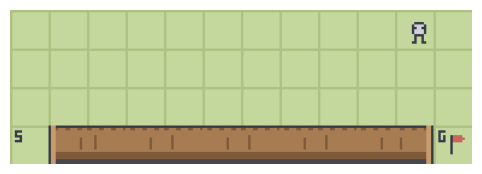

State:  10    [-8.07413288 -6.54229974 -7.77075283 -9.30000921]
Step 13: observation=11, reward=-1, done=False


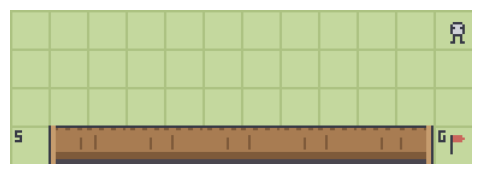

State:  11    [-6.72649735 -6.67240684 -5.47187042 -8.13926046]
Step 14: observation=23, reward=-1, done=False


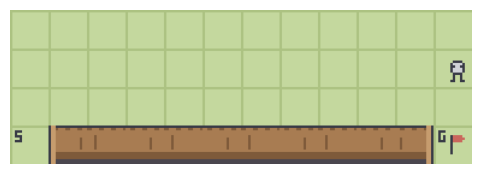

State:  23    [-7.12563978 -5.20458446 -3.30171599 -7.01725472]
Step 15: observation=35, reward=-1, done=False


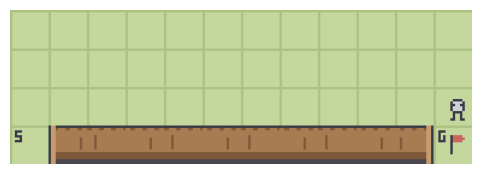

State:  35    [-5.28324359 -3.45031608 -1.         -7.66768075]
Step 16: observation=47, reward=-1, done=True


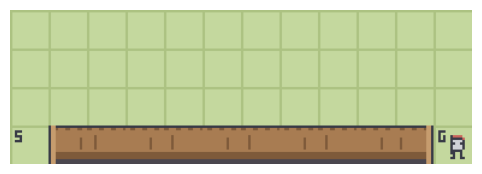

Reward  -17.0 | steps 17


-17.0

In [6]:
agent_sarsa.follow_best_policy()

## Q-learning (off-policy)

$$Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \alpha\,[\,r_{t+1} + \gamma\, \max_a Q(s_{t+1},a) - Q(s_t,a_t)\,]$$

Same hyperparameters as SARSA, so the two methods can be compared.

In [7]:
np.random.seed(42)
agent_q = Agent()
agent_q.lr = 0.1
agent_q.exp_rate = 0.3
agent_q.playQ_learning(2000)
agent_q.showValues()

---------STATE VALUES------------
----------------------------------
| -13.59 | -12.85 | -11.94 | -10.98 | -9.99  | -8.99  | -8.00  | -7.00  | -6.00  | -5.00  | -4.00  | -3.00  | 
----------------------------------
| -13.00 | -12.00 | -11.00 | -10.00 | -9.00  | -8.00  | -7.00  | -6.00  | -5.00  | -4.00  | -3.00  | -2.00  | 
----------------------------------
| -12.00 | -11.00 | -10.00 | -9.00  | -8.00  | -7.00  | -6.00  | -5.00  | -4.00  | -3.00  | -2.00  | -1.00  | 
----------------------------------
| -13.00 | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 0.00   | 
----------------------------------


### Best Q-learning policy – sequence of images

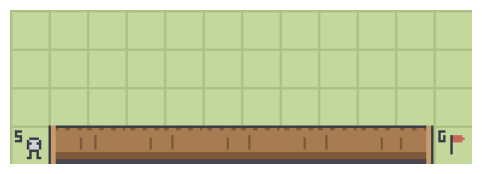

State:  36    [ -13. -113.  -14.  -14.]
Step 0: observation=24, reward=-1, done=False


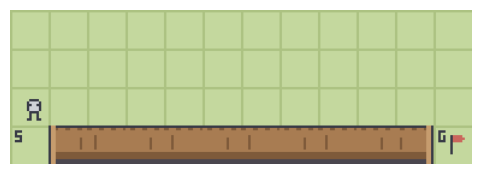

State:  24    [-13.99999993 -12.         -14.         -13.        ]
Step 1: observation=25, reward=-1, done=False


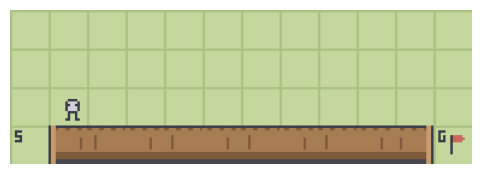

State:  25    [ -13.  -11. -113.  -13.]
Step 2: observation=26, reward=-1, done=False


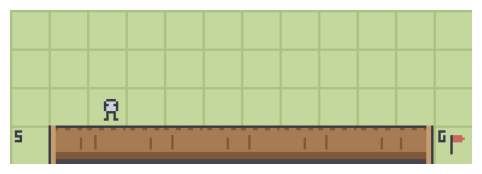

State:  26    [ -12.  -10. -113.  -12.]
Step 3: observation=27, reward=-1, done=False


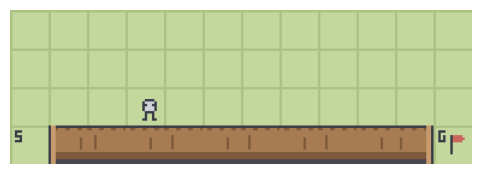

State:  27    [ -11.   -9. -113.  -11.]
Step 4: observation=28, reward=-1, done=False


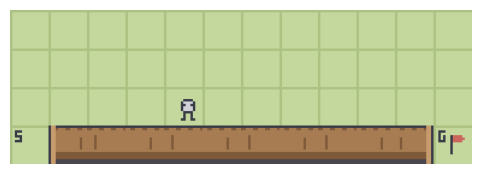

State:  28    [ -10.   -8. -113.  -10.]
Step 5: observation=29, reward=-1, done=False


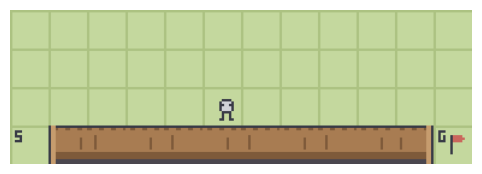

State:  29    [  -9.   -7. -113.   -9.]
Step 6: observation=30, reward=-1, done=False


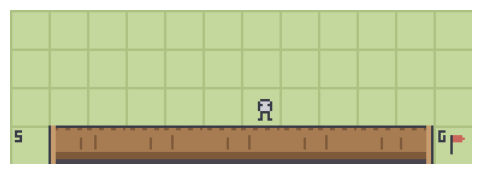

State:  30    [  -7.99999999   -6.         -112.99999999   -8.        ]
Step 7: observation=31, reward=-1, done=False


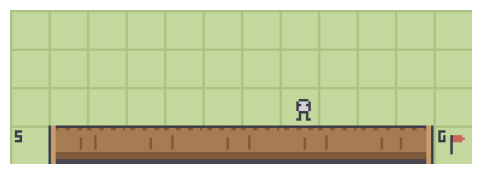

State:  31    [  -7.           -5.         -112.99999991   -6.99999999]
Step 8: observation=32, reward=-1, done=False


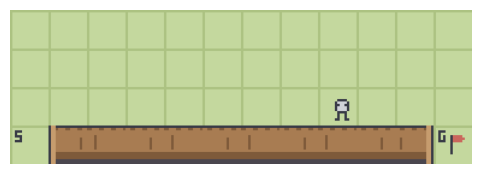

State:  32    [  -6.           -4.         -112.99999995   -5.99999999]
Step 9: observation=33, reward=-1, done=False


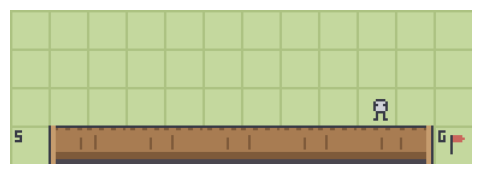

State:  33    [  -4.99999986   -3.         -112.9999999    -4.99999983]
Step 10: observation=34, reward=-1, done=False


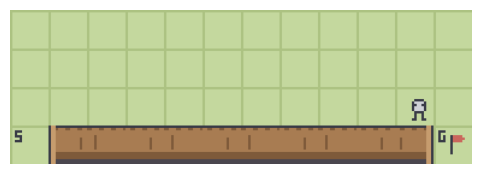

State:  34    [  -3.99999995   -2.         -112.99999835   -3.99999998]
Step 11: observation=35, reward=-1, done=False


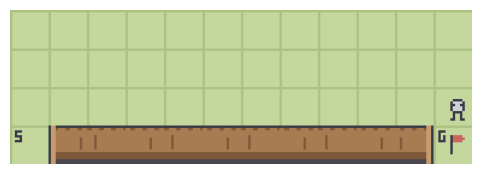

State:  35    [-3. -2. -1. -3.]
Step 12: observation=47, reward=-1, done=True


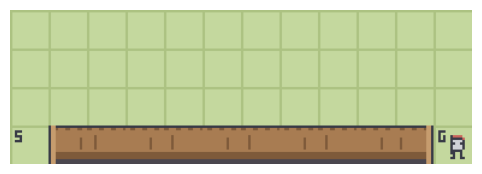

Reward  -13.0 | steps 13


-13.0

In [8]:
agent_q.follow_best_policy()

## Visualization of the best policies

### Policy maps

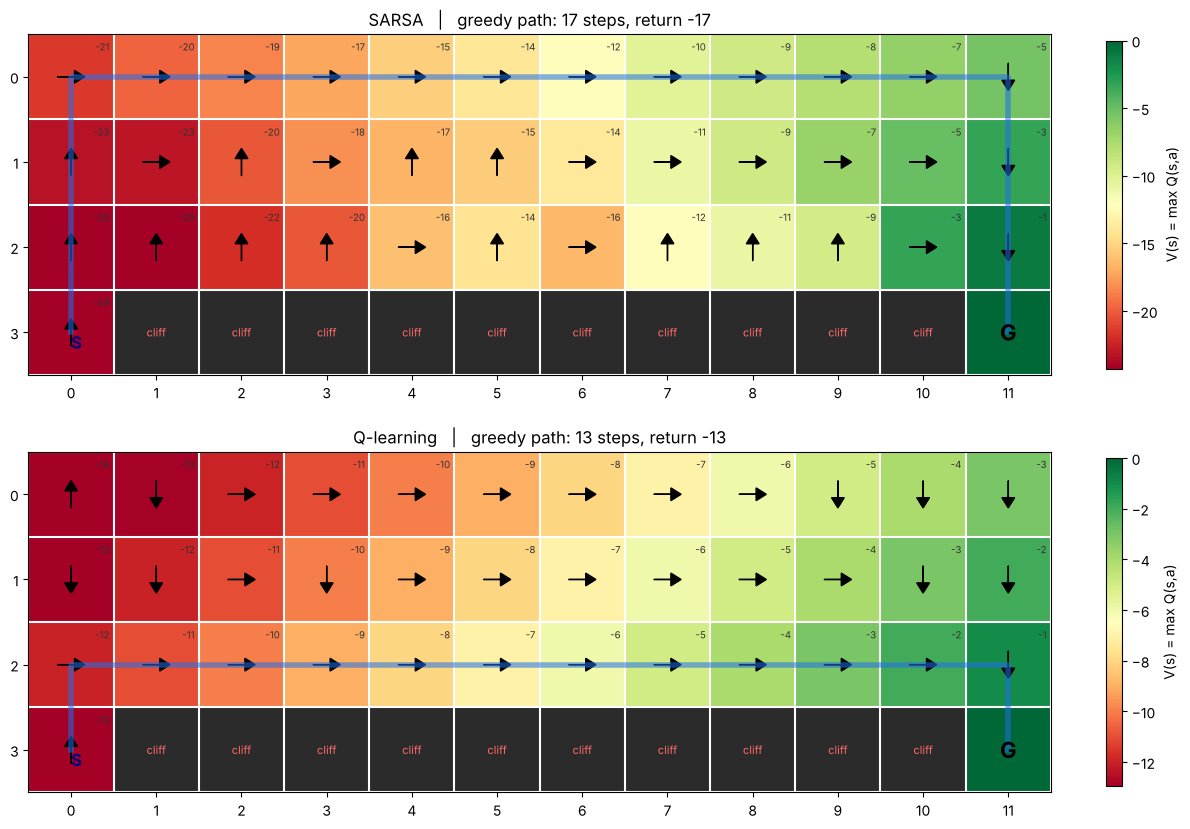

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5))
plot_policy_map(agent_sarsa, 'SARSA', axes[0])
plot_policy_map(agent_q, 'Q-learning', axes[1])
plt.tight_layout()
plt.show()

### Episode as a film strip

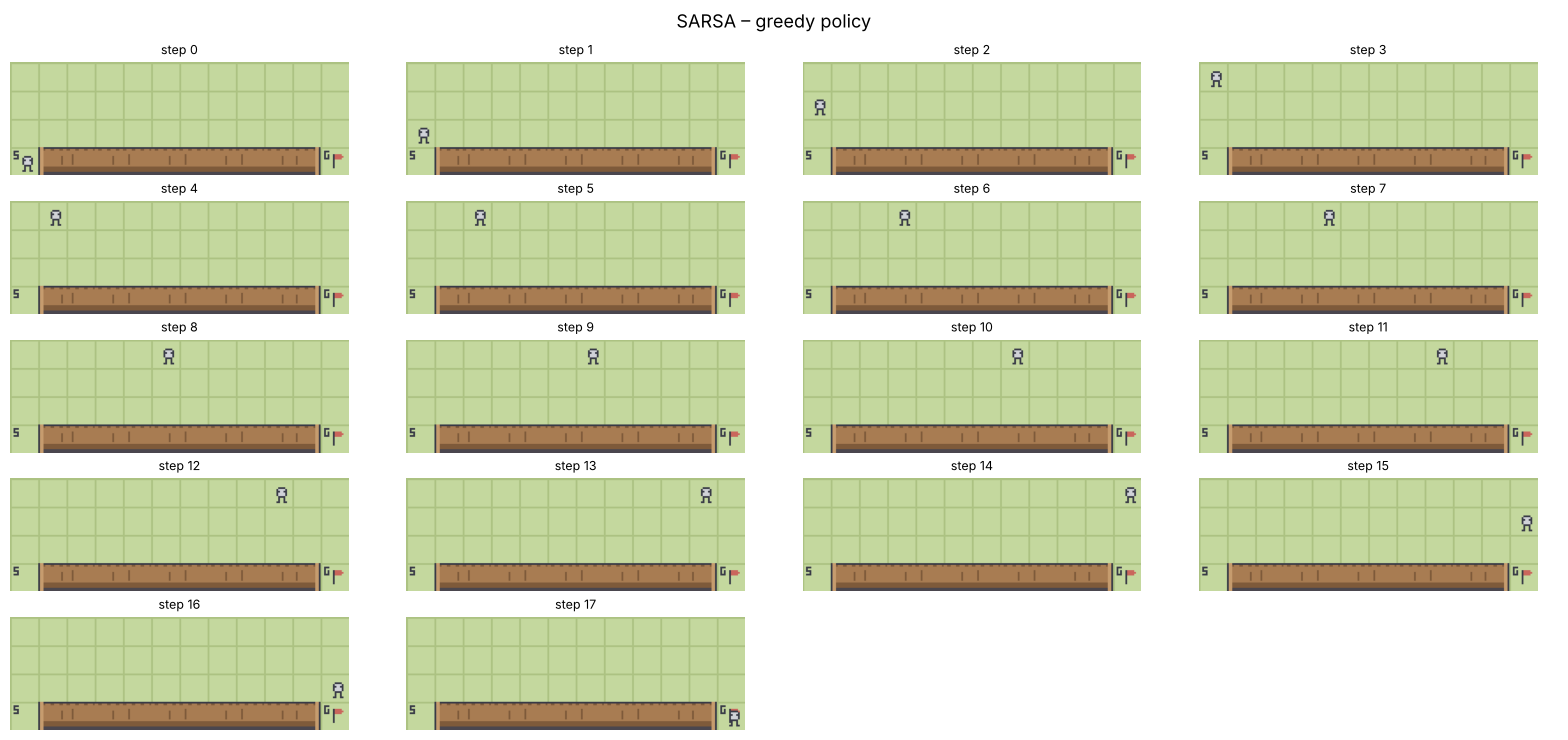

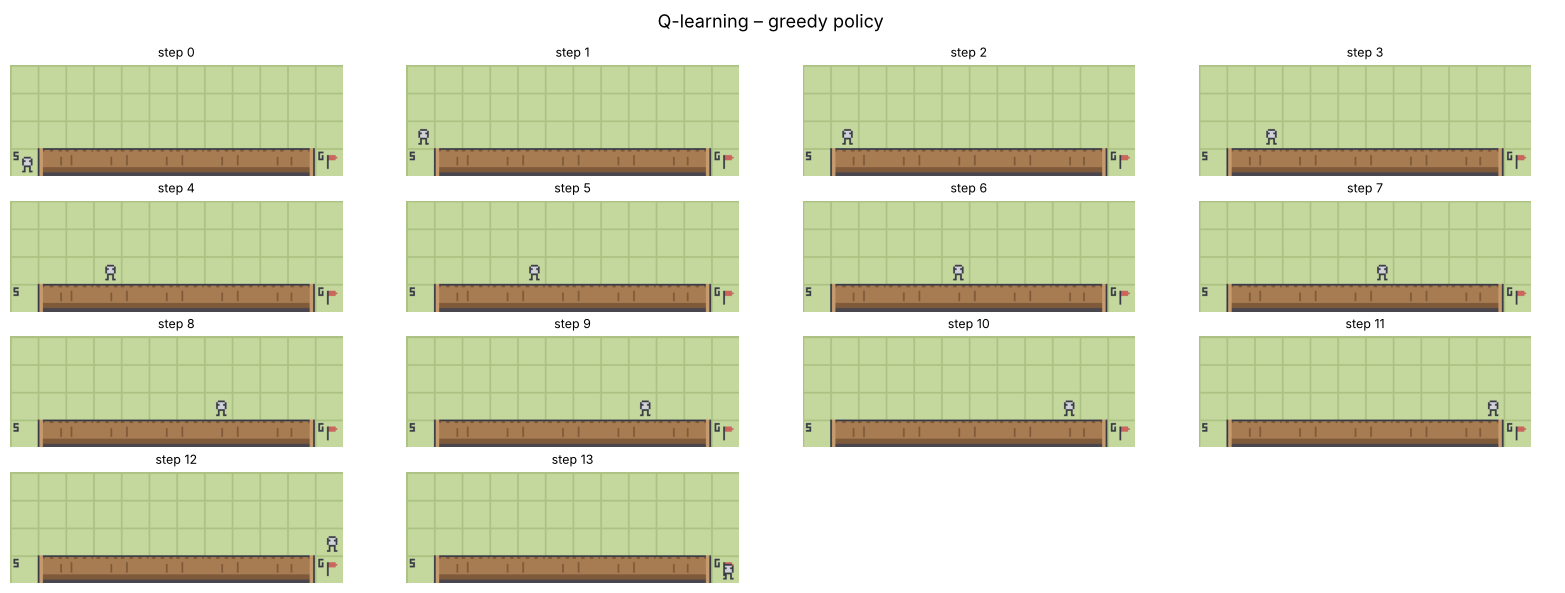

In [10]:
show_filmstrip(agent_sarsa.frames, 'SARSA – greedy policy')
show_filmstrip(agent_q.frames, 'Q-learning – greedy policy')

### Video (animated GIF)

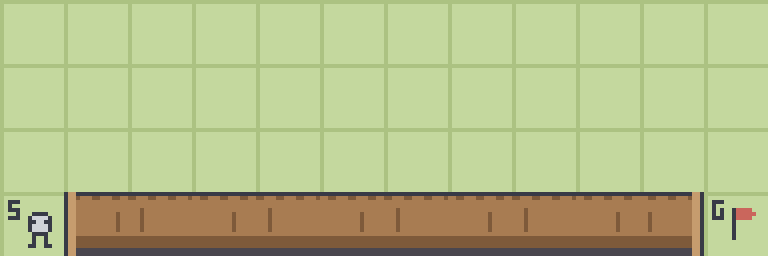

In [11]:
show_animation(agent_sarsa.frames, 'sarsa_policy.gif')

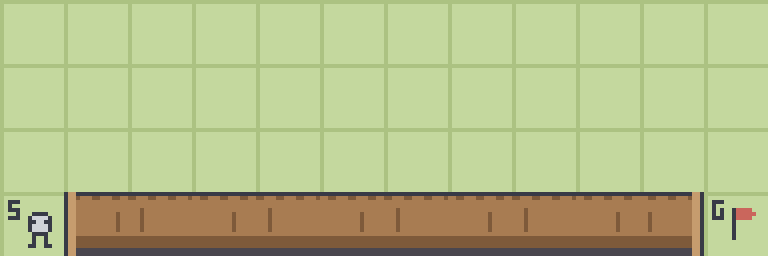

In [12]:
show_animation(agent_q.frames, 'qlearning_policy.gif')

### Learning curves

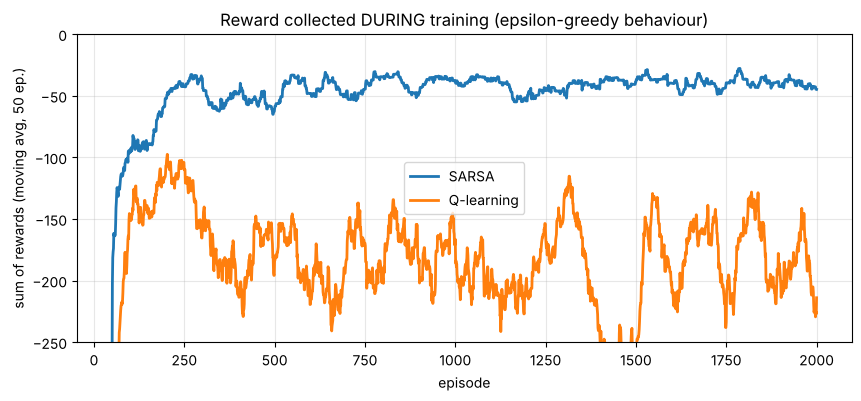

In [13]:
plot_learning_curves({'SARSA': agent_sarsa.episode_rewards, 'Q-learning': agent_q.episode_rewards})

## Conclusions

* **Q-learning** learns the **optimal path along the edge of the cliff** (13 steps, return −13).
  Its target uses `max Q(s', ·)`, i.e. it assumes the agent will act greedily from the next step on – random ε-moves are ignored.
* **SARSA** learns a **safer path along the top row** (17 steps, return −17).
  Its target uses the action that is really taken, so the risk of a random step into the cliff (ε = 0.3) is included in Q – states next to the cliff get low values.
* **During training** SARSA collects much more reward: Q-learning walks along the cliff and falls whenever ε picks *down*.
* With ε → 0 both methods would converge to the same optimal policy.